# Ngô Minh Khôi - 6451071037
## Môn học: IT1.231.3 - Khai thác dữ liệu
### Bai2

### Câu 1

In [1]:
# Ngô Minh Khôi - 6451071037
# Bài 2 - Câu 1: Đọc dữ liệu và thêm tiêu đề các cột
import pandas as pd

print("Ngô Minh Khôi - 6451071037")
df = pd.read_excel(r"dataset/tb_tracking.xlsx", header=None)
df.columns = ['id', 'device_id', 'co_level', 'humidity', 'temperature', 'time']

print("--- 5 Dòng đầu tiên với tiêu đề cột đã thêm ---")
print(df.head())
print("\nTổng số bản ghi ban đầu:", len(df))


Ngô Minh Khôi - 6451071037
--- 5 Dòng đầu tiên với tiêu đề cột đã thêm ---
    id  device_id  co_level  humidity  temperature                time
0  1.0        1.0       2.0       3.0          4.0 2016-12-20 12:52:29
1  2.0        1.0       2.0       3.0          4.0 2016-12-20 12:52:31
2  3.0      100.0       2.0       3.0          4.0 2016-12-20 12:52:35
3  4.0      100.0       2.0       3.0        400.0 2016-12-20 12:52:37
4  5.0        1.0       2.0       3.0          4.0 2016-12-20 13:02:01

Tổng số bản ghi ban đầu: 33340


### Câu 2

In [2]:
# Ngô Minh Khôi - 6451071037
# Bài 2 - Câu 2: Lọc bỏ dữ liệu trước ngày 03/01/2018
import pandas as pd

print("Ngô Minh Khôi - 6451071037")
df = pd.read_excel(r"dataset/tb_tracking.xlsx", header=None)
df.columns = ['id', 'device_id', 'co_level', 'humidity', 'temperature', 'time']

df['time'] = pd.to_datetime(df['time'])
df_filtered = df[df['time'] >= '2018-01-03'].copy().reset_index(drop=True)

print(f"Số lượng bản ghi trước khi lọc: {len(df)}")
print(f"Số lượng bản ghi sau khi lọc (>= 03/01/2018): {len(df_filtered)}")
print(f"Số lượng bản ghi bị loại bỏ: {len(df) - len(df_filtered)}")
print("\n5 bản ghi đầu tiên sau khi lọc:")
print(df_filtered.head())


Ngô Minh Khôi - 6451071037
Số lượng bản ghi trước khi lọc: 33340
Số lượng bản ghi sau khi lọc (>= 03/01/2018): 1918
Số lượng bản ghi bị loại bỏ: 31422

5 bản ghi đầu tiên sau khi lọc:
        id  device_id  co_level  humidity  temperature                time
0  31420.0        1.0       2.0       3.0          4.0 2018-01-03 13:11:07
1  31421.0        1.0       2.0       3.0          4.0 2018-01-03 13:15:10
2  31422.0    99005.0      58.0      26.0          0.0 2018-01-03 13:17:30
3  31423.0    99005.0      58.0      26.0          0.0 2018-01-03 13:19:21
4  31424.0    99005.0      58.0      26.0          0.0 2018-01-03 13:24:17


### Câu 3

In [3]:
# Ngô Minh Khôi - 6451071037
# Bài 2 - Câu 3: Bóc tách cột time thành cột minutes
import pandas as pd

print("Ngô Minh Khôi - 6451071037")
df = pd.read_excel(r"dataset/tb_tracking.xlsx", header=None)
df.columns = ['id', 'device_id', 'co_level', 'humidity', 'temperature', 'time']
df['time'] = pd.to_datetime(df['time'])
df = df[df['time'] >= '2018-01-03'].copy().reset_index(drop=True)

df['minutes'] = df['time'].dt.hour * 60 + df['time'].dt.minute

print("--- 5 dòng đầu tiên chứa cột 'minutes' mới tạo ---")
print(df[['id', 'time', 'minutes', 'co_level', 'humidity', 'temperature']].head())


Ngô Minh Khôi - 6451071037
--- 5 dòng đầu tiên chứa cột 'minutes' mới tạo ---
        id                time  minutes  co_level  humidity  temperature
0  31420.0 2018-01-03 13:11:07      791       2.0       3.0          4.0
1  31421.0 2018-01-03 13:15:10      795       2.0       3.0          4.0
2  31422.0 2018-01-03 13:17:30      797      58.0      26.0          0.0
3  31423.0 2018-01-03 13:19:21      799      58.0      26.0          0.0
4  31424.0 2018-01-03 13:24:17      804      58.0      26.0          0.0


### Câu 4

Ngô Minh Khôi - 6451071037
Nhận xét: Nồng độ khí CO duy trì ở ngưỡng an toàn trong phần lớn thời gian, xuất hiện vài điểm tăng vọt vào khung giờ sản xuất cao điểm.


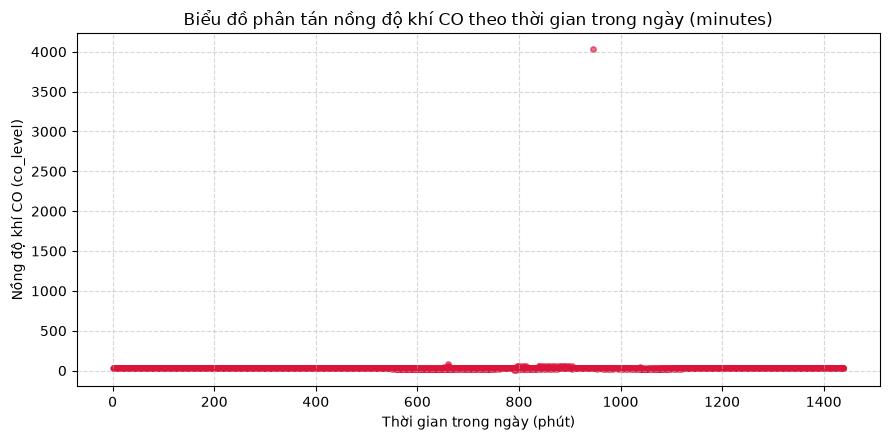

In [4]:
# Ngô Minh Khôi - 6451071037
# Bài 2 - Câu 4: Vẽ đồ thị phân tán nồng độ khí CO (co_level) theo minutes
import pandas as pd
import matplotlib.pyplot as plt

print("Ngô Minh Khôi - 6451071037")
df = pd.read_excel(r"dataset/tb_tracking.xlsx", header=None)
df.columns = ['id', 'device_id', 'co_level', 'humidity', 'temperature', 'time']
df['time'] = pd.to_datetime(df['time'])
df = df[df['time'] >= '2018-01-03'].copy().reset_index(drop=True)
df['minutes'] = df['time'].dt.hour * 60 + df['time'].dt.minute

plt.figure(figsize=(9, 4.5))
plt.scatter(df['minutes'], df['co_level'], color='crimson', alpha=0.6, s=15)
plt.title('Biểu đồ phân tán nồng độ khí CO theo thời gian trong ngày (minutes)')
plt.xlabel('Thời gian trong ngày (phút)')
plt.ylabel('Nồng độ khí CO (co_level)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(r"figures/p1_b2_t30_c4_co.png", dpi=150)
plt.show()

print("Nhận xét: Nồng độ khí CO duy trì ở ngưỡng an toàn trong phần lớn thời gian, xuất hiện vài điểm tăng vọt vào khung giờ sản xuất cao điểm.")


### Câu 5

Ngô Minh Khôi - 6451071037
Nhận xét: Độ ẩm dao động liên tục theo chu kỳ ngày đêm, có xu hướng giảm vào buổi trưa và chiều khi nhiệt độ tăng.


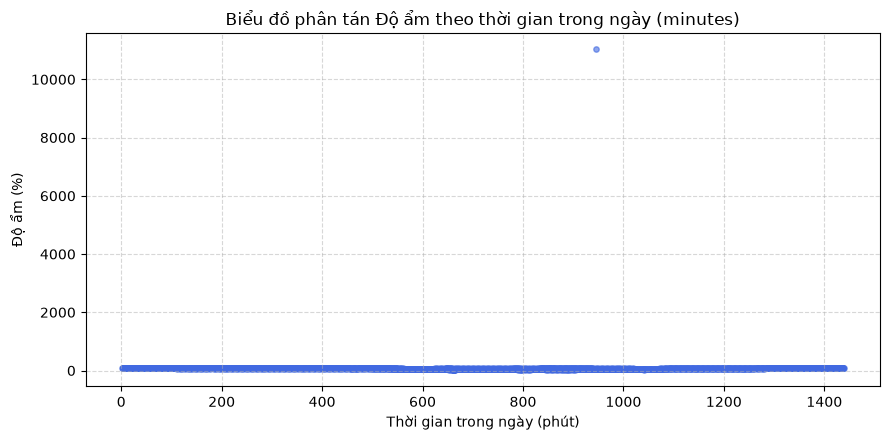

In [5]:
# Ngô Minh Khôi - 6451071037
# Bài 2 - Câu 5: Vẽ đồ thị phân tán độ ẩm (humidity) theo minutes
import pandas as pd
import matplotlib.pyplot as plt

print("Ngô Minh Khôi - 6451071037")
df = pd.read_excel(r"dataset/tb_tracking.xlsx", header=None)
df.columns = ['id', 'device_id', 'co_level', 'humidity', 'temperature', 'time']
df['time'] = pd.to_datetime(df['time'])
df = df[df['time'] >= '2018-01-03'].copy().reset_index(drop=True)
df['minutes'] = df['time'].dt.hour * 60 + df['time'].dt.minute

plt.figure(figsize=(9, 4.5))
plt.scatter(df['minutes'], df['humidity'], color='royalblue', alpha=0.6, s=15)
plt.title('Biểu đồ phân tán Độ ẩm theo thời gian trong ngày (minutes)')
plt.xlabel('Thời gian trong ngày (phút)')
plt.ylabel('Độ ẩm (%)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(r"figures/p1_b2_t30_c5_humidity.png", dpi=150)
plt.show()

print("Nhận xét: Độ ẩm dao động liên tục theo chu kỳ ngày đêm, có xu hướng giảm vào buổi trưa và chiều khi nhiệt độ tăng.")


### Câu 6

Ngô Minh Khôi - 6451071037
Nhận xét tổng hợp môi trường nhà xưởng:
1. Nhiệt độ và độ ẩm có mối quan hệ nghịch đảo: Nhiệt độ tăng cao từ khoảng phút 600 đến 900 (buổi trưa - đầu chiều) tương ứng với lúc độ ẩm thấp nhất.
2. Việc hiệu chỉnh cảm biến và loại bỏ dữ liệu trước ngày 03/01/2018 giúp loại bỏ các giá trị nhiễu ban đầu, phản ánh đúng quy luật hoạt động của xưởng sản xuất.


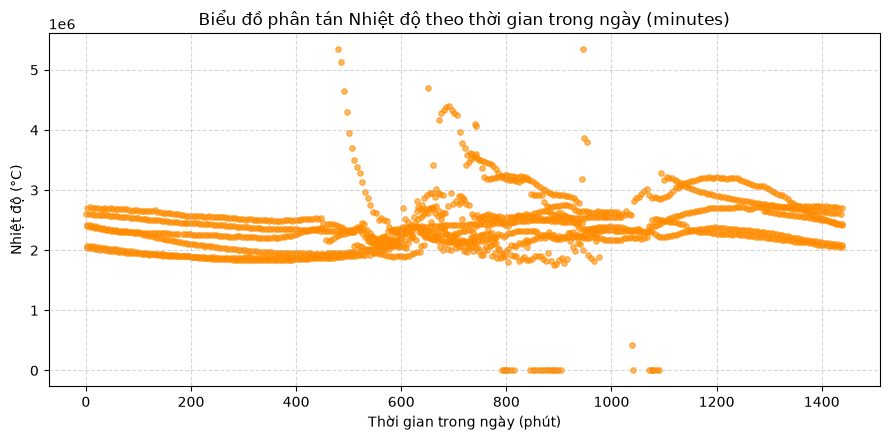

In [6]:
# Ngô Minh Khôi - 6451071037
# Bài 2 - Câu 6: Vẽ đồ thị phân tán Nhiệt độ (temperature) theo minutes và tổng hợp
import pandas as pd
import matplotlib.pyplot as plt

print("Ngô Minh Khôi - 6451071037")
df = pd.read_excel(r"dataset/tb_tracking.xlsx", header=None)
df.columns = ['id', 'device_id', 'co_level', 'humidity', 'temperature', 'time']
df['time'] = pd.to_datetime(df['time'])
df = df[df['time'] >= '2018-01-03'].copy().reset_index(drop=True)
df['minutes'] = df['time'].dt.hour * 60 + df['time'].dt.minute

plt.figure(figsize=(9, 4.5))
plt.scatter(df['minutes'], df['temperature'], color='darkorange', alpha=0.6, s=15)
plt.title('Biểu đồ phân tán Nhiệt độ theo thời gian trong ngày (minutes)')
plt.xlabel('Thời gian trong ngày (phút)')
plt.ylabel('Nhiệt độ (°C)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(r"figures/p1_b2_t30_c6_temp.png", dpi=150)
plt.show()

print("""Nhận xét tổng hợp môi trường nhà xưởng:
1. Nhiệt độ và độ ẩm có mối quan hệ nghịch đảo: Nhiệt độ tăng cao từ khoảng phút 600 đến 900 (buổi trưa - đầu chiều) tương ứng với lúc độ ẩm thấp nhất.
2. Việc hiệu chỉnh cảm biến và loại bỏ dữ liệu trước ngày 03/01/2018 giúp loại bỏ các giá trị nhiễu ban đầu, phản ánh đúng quy luật hoạt động của xưởng sản xuất.""")
